<a href="https://colab.research.google.com/github/Soheilp86/Statistical-Machine-Learning/blob/main/61_Neural_Networks_Intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Networks with scikit-learn

In this notebook we will

1. Train a neural network (`MLPClassifier`) to recognize **handwritten digits**,
2. Look inside the trained network: its weights, biases and number of parameters,
3. Get comfortable with the **parameters** that control a network, one at a time,
4. Tune a network with cross-validation,
5. **Your turn:** apply everything to the **breast cancer** dataset.

In [1]:
## Data manipulation and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

## Datasets
from sklearn.datasets import load_digits, load_breast_cancer

## Model creation and training
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning

## Performance metrics
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

## 1. **The Handwritten Digits Dataset**

The digits dataset contains 1,797 small images of handwritten digits (0 to 9). Each image is 8 × 8 = **64 pixels**, and each pixel is a number from 0 (white) to 16 (black).

To use an image as model input, we **flatten** it into a row of 64 numbers. So:

- `X` has shape (1797, 64): one row per image, one column per pixel,
- `y` holds the digit shown in each image.

In [2]:
digits = load_digits()
X = digits.data      # 64 pixel values per image
y = digits.target    # the digit 0-9

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", np.unique(y))

X shape: (1797, 64)
y shape: (1797,)
Classes: [0 1 2 3 4 5 6 7 8 9]


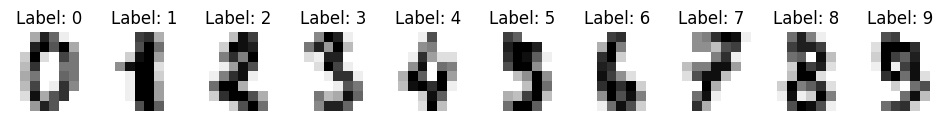

In [3]:
# Show the first 10 images with their labels
fig, axes = plt.subplots(1, 10, figsize=(12, 2))
for ax, image, label in zip(axes, digits.images, y):
    ax.imshow(image, cmap="gray_r")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.show()

__How does this connect to the network?__

- The **input layer** has one neuron per feature: **64** inputs.
- The **output layer** has one neuron per class: **10** outputs. sklearn uses a softmax on the output, exactly like multi-class logistic regression, so we get one probability per digit.
- **We** choose the hidden layers in between.

## 2. **Prepare the Data**

We split the data into training and test sets, then **scale** the features.

__Why scale?__ A neuron computes $z = \mathbf{w}^\top\mathbf{x} + b$. If one feature is in the thousands and another is between 0 and 1, the large feature dominates $z$ and training becomes slow and unstable. Neural networks train much better when every feature has mean 0 and standard deviation 1. We fit the scaler on the **training data only**, so no information leaks from the test set.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Keep an unscaled copy of the test images so we can plot them later
X_test_images = X_test.copy()

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # learn mean and std from the training data
X_test = scaler.transform(X_test)         # apply the same scaling to the test data

print("Training set:", X_train.shape, "  Test set:", X_test.shape)

Training set: (1437, 64)   Test set: (360, 64)


## 3. **Baseline: Logistic Regression**

Before building a network, let's see how a model we already know performs. Multi-class logistic regression is a network with **no hidden layer**: 64 inputs connected directly to 10 outputs.

In [5]:
lr = LogisticRegression(max_iter=5000)
lr.fit(X_train, y_train)

lr_test_acc = accuracy_score(y_test, lr.predict(X_test))
lr_params = lr.coef_.size + lr.intercept_.size
print(f"Logistic regression test accuracy: {lr_test_acc:.3f}   ({lr_params} parameters)")

Logistic regression test accuracy: 0.972   (650 parameters)


<Axes: >

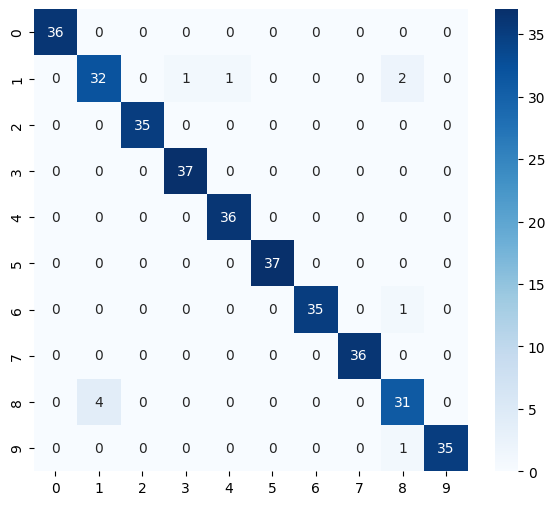

In [8]:
# Confusion matrix for LR
y_pred = lr.predict(X_test)
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")

## 4. **Your First Neural Network**

`MLPClassifier` stands for **multi-layer perceptron** classifier: a network of layers of neurons, exactly what we drew in the lecture. It uses the same `fit` / `predict` / `score` interface as every other sklearn model.

The most important parameters:

- `hidden_layer_sizes=(32,)`: one hidden layer with 32 neurons. `(64, 32)` would mean two hidden layers, with 64 and 32 neurons.
- `activation="relu"`: the activation function used in the hidden layers.
- `max_iter=1000`: the maximum number of training passes over the data.
- `random_state=0`: the network starts from random weights; fixing the seed makes results reproducible.

In [6]:
mlp = MLPClassifier(hidden_layer_sizes=(32,), activation="relu", max_iter=1000, random_state=0)
mlp.fit(X_train, y_train)

print(f"Training accuracy: {mlp.score(X_train, y_train):.3f}")
print(f"Test accuracy:     {mlp.score(X_test, y_test):.3f}")

Training accuracy: 1.000
Test accuracy:     0.978


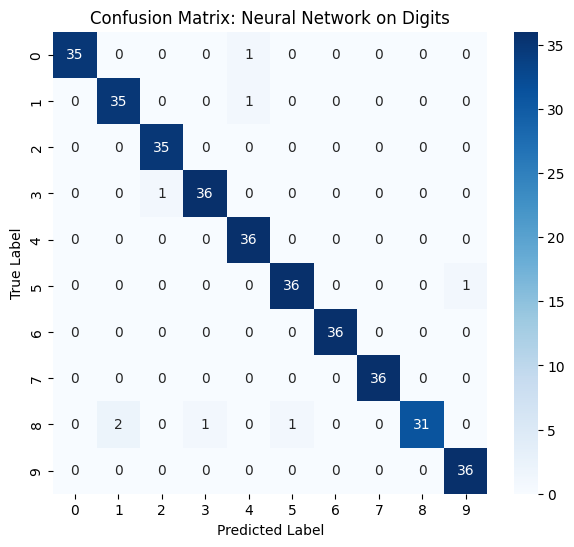

In [7]:
# Confusion matrix
y_pred = mlp.predict(X_test)
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix: Neural Network on Digits")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Let's look at the images the network got wrong. Are they hard for a human, too?

Number of mistakes: 10 out of 360


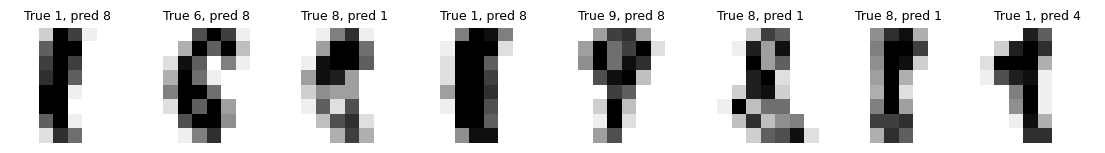

In [9]:
wrong = np.where(y_pred != y_test)[0]
print("Number of mistakes:", len(wrong), "out of", len(y_test))

fig, axes = plt.subplots(1, min(8, len(wrong)), figsize=(14, 2.2))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(X_test_images[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"True {y_test[i]}, pred {y_pred[i]}", fontsize=9)
    ax.axis("off")
plt.show()

Like logistic regression, the network gives a probability for each class. `predict` simply picks the class with the highest probability.

In [10]:
probs = mlp.predict_proba(X_test[:1])[0]
print("Probabilities for the first test image:", np.round(probs, 3))
print("Predicted digit:", probs.argmax(), "   True digit:", y_test[0])

Probabilities for the first test image: [0.    0.    0.    0.    0.    0.994 0.    0.    0.    0.005]
Predicted digit: 5    True digit: 5


## 5. **Look Inside the Network**

A trained network is just its weights and biases.

- `mlp.coefs_` is a list with one weight matrix per layer.
- `mlp.intercepts_` is a list with one bias vector per layer.

__Careful:__ sklearn stores each weight matrix as (inputs × neurons). That is the **transpose** of the $W$ we used in the lecture and worksheet, where each row is one neuron.

In [11]:
for i, (W, b) in enumerate(zip(mlp.coefs_, mlp.intercepts_), start=1):
    print(f"Layer {i}: weights {W.shape}, biases {b.shape}")

Layer 1: weights (64, 32), biases (32,)
Layer 2: weights (32, 10), biases (10,)


Count the parameters by hand first:

- Hidden layer: 64 inputs × 32 neurons + 32 biases = 2,080
- Output layer: 32 inputs × 10 neurons + 10 biases = 330
- Total: **2,410**

We will count parameters often, so let's write a small helper function.

In [12]:
def count_params(model):
    # every weight plus every bias, summed over all layers
    return sum(W.size + b.size for W, b in zip(model.coefs_, model.intercepts_))

print("Neural network parameters:", count_params(mlp))
print("Logistic regression parameters:", lr_params)

Neural network parameters: 2410
Logistic regression parameters: 650


### How the network learns: the loss curve

Training starts from random weights. In each **iteration** (one pass over the training data) the network nudges its weights to reduce a **loss**: the same log-loss that logistic regression minimizes. `mlp.loss_curve_` records the loss after every iteration. How this nudging works (gradient descent) is our next lecture.

Iterations used: 213


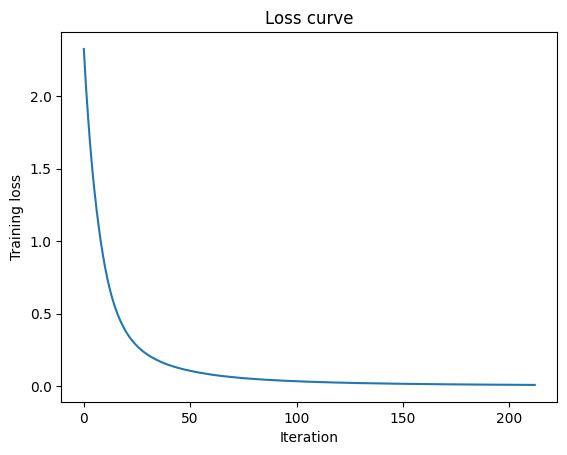

In [13]:
print("Iterations used:", mlp.n_iter_)

plt.plot(mlp.loss_curve_)
plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.title("Loss curve")
plt.show()

## 6. **Getting Comfortable with the Parameters**

Here are the parameters you will change most often:

| Parameter | What it controls | Default |
|---|---|---|
| `hidden_layer_sizes` | number of hidden layers and neurons in each | `(100,)` |
| `activation` | activation in the hidden layers: `"relu"`, `"tanh"`, `"logistic"` (sigmoid), `"identity"` (none) | `"relu"` |
| `max_iter` | maximum number of training iterations | `200` |
| `learning_rate_init` | how big a step the weights take in each update | `0.001` |
| `alpha` | strength of the penalty on large weights (regularization, like ridge regression) | `0.0001` |
| `early_stopping` | stop when the score on a held-out validation set stops improving | `False` |
| `random_state` | the random starting weights | `None` |

To keep the experiments short, this helper trains one network with the parameters you give it and reports the results.

The differences are small but real. When you compare two settings, make sure the difference is bigger than this seed-to-seed noise, or use cross-validation (next section).

## 7. **Tuning with Cross-Validation**

Instead of trying settings by hand, we can let `GridSearchCV` try every combination and pick the best one using cross-validation, as in the cross-validation notebook.

We put the scaler and the network into a `Pipeline`. Then the scaler is re-fit inside every fold, so the validation fold never leaks into the scaling. Parameter names get the step name as a prefix: `mlp__alpha` means "the `alpha` of the step called `mlp`".

In [16]:
# Start again from the unscaled data: the pipeline does the scaling
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(max_iter=1000, random_state=0)),
])

param_grid = {
    "mlp__hidden_layer_sizes": [(16,), (64,), (64, 32)],
    "mlp__alpha": [0.0001, 0.01, 1],
}

grid = GridSearchCV(pipe, param_grid, cv=3, n_jobs=-1)
grid.fit(X_train_raw, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best cross-validation accuracy: {grid.best_score_:.3f}")
print(f"Test accuracy of the best model: {grid.score(X_test_raw, y_test):.3f}")

Best parameters: {'mlp__alpha': 1, 'mlp__hidden_layer_sizes': (64,)}
Best cross-validation accuracy: 0.971
Test accuracy of the best model: 0.981


In [17]:
# All combinations, best first
cv_results = pd.DataFrame(grid.cv_results_)
cv_results[["param_mlp__hidden_layer_sizes", "param_mlp__alpha", "mean_test_score"]].sort_values(
    "mean_test_score", ascending=False
)

,param_mlp__hidden_layer_sizes,param_mlp__alpha,mean_test_score
7,"(64,)",1.0000,0.971468
8,"(64, 32)",1.0000,0.970077
5,"(64, 32)",0.0100,0.969381
2,"(64, 32)",0.0001,0.968685
1,"(64,)",0.0001,0.967989
4,"(64,)",0.0100,0.967989
6,"(16,)",1.0000,0.965901
3,"(16,)",0.0100,0.964509
0,"(16,)",0.0001,0.963814


## 8. **Your Turn: Breast Cancer**

Now apply everything to the breast cancer dataset from the classification notebook: 569 patients, 30 features measured from images of cell nuclei.

In sklearn's version of this dataset the target is **0 = malignant** and **1 = benign**. In medicine, missing a malignant tumor is the most costly mistake, so besides accuracy we will look at the **recall for malignant tumors**: the fraction of malignant tumors the model catches.

### 8.1 Load, split and scale

1. Load the data with `load_breast_cancer()`.
2. Print the shapes of `X` and `y`, and how many patients are in each class (`np.bincount(y)`).
3. Split with `test_size=0.2`, `stratify=y`, `random_state=42`.
4. Scale with `StandardScaler` (fit on the training data only).

In [ ]:
# Load the data


# Shapes and class counts


# Split


# Scale

### 8.2 Baseline: logistic regression

Train `LogisticRegression(max_iter=5000)`. Report its test accuracy and its recall for malignant tumors: `recall_score(y_test, y_pred, pos_label=0)`.

In [ ]:
# Train logistic regression


# Test accuracy and malignant recall

### 8.3 Your first network

1. Train `MLPClassifier(hidden_layer_sizes=(16,), max_iter=2000, random_state=0)`.
2. Report training accuracy, test accuracy and malignant recall.
3. Plot the confusion matrix.
4. Count the parameters with `count_params`. Logistic regression has 31 (30 weights and 1 bias). Check the count by hand: (30 × 16 + 16) + (16 × 1 + 1).

In [ ]:
# Train the network


# Train accuracy, test accuracy, malignant recall


# Confusion matrix


# Number of parameters

### 8.4 Learning rate and the loss curve

Train three networks with `hidden_layer_sizes=(16,)` and `learning_rate_init` = `0.0001`, `0.001` and `0.1` (use `max_iter=300`). Plot their three loss curves on one figure, as in Section 6.4. What do you notice?

In [ ]:
# Loss curves for three learning rates

### 8.5 Tune with cross-validation

Build a `Pipeline` with a `StandardScaler` and an `MLPClassifier(max_iter=2000, random_state=0)`, then use `GridSearchCV` with `cv=5` to search over:

- `hidden_layer_sizes`: `(8,)`, `(32,)`, `(32, 16)`
- `alpha`: `0.0001`, `0.1`, `1`

Use the **unscaled** data (the pipeline scales it). Report the best parameters, the best cross-validation accuracy, and the test accuracy and malignant recall of the best model.

In [ ]:
# Unscaled split (same settings as 8.1)


# Pipeline and parameter grid


# Grid search


# Best parameters, CV accuracy, test accuracy, malignant recall